# Satellite Zoom Level Comparison for Road Segments

Compares Fixed Zoom 18, Fixed Zoom 19 and Auto Zoom satellite images (Google Maps Static API) for three groups of road segments in Western Australia, to choose the image area used for feature extraction.

All satellite images are © Google and its imagery providers. The Google logo and the imagery attribution printed on each image are kept and must not be cropped out of any figure used in reports.

In [2]:
import os

# The API key is read from the environment and is never stored in this notebook.
# Local:  export GOOGLE_MAPS_API_KEY="..." before starting Jupyter
# Colab:  add a secret named GOOGLE_MAPS_API_KEY (key icon in the left panel)
MAP_API = os.environ.get("GOOGLE_MAPS_API_KEY")

if not MAP_API:
    try:
        from google.colab import userdata
        MAP_API = userdata.get("GOOGLE_MAPS_API_KEY")
    except Exception:
        pass

if not MAP_API:
    raise RuntimeError("Set the GOOGLE_MAPS_API_KEY environment variable (or Colab secret) before running.")

### Calculate the midpoint coordinates of the road segment.

In [3]:
def calculate_center(start_lat, start_long, end_lat, end_long):
    """
    Calculate the midpoint coordinates of the road segment.
    Returns a tuple: (center_lat, center_long)
    """
    center_lat = (start_lat + end_lat) / 2.0
    center_long = (start_long + end_long) / 2.0

    return center_lat, center_long


### Calculate the optimal zoom level to fit the road segment within the image.

In [4]:
import math

def calculate_zoom(start_lat, start_long, end_lat, end_long, img_size=640, default_zoom=18):
    """
    Calculate the optimal zoom level to fit the road segment within the image.
    Returns an integer representing the zoom level.
    """
    lat_diff = abs(start_lat - end_lat)
    long_diff = abs(start_long - end_long)

    # Return default zoom if the start and end points are exactly the same
    if lat_diff == 0 and long_diff == 0:
        return default_zoom

    # Reverse calculate the required zoom level using Mercator projection logic
    zoom_lat = math.log2((180.0 * img_size) / (256.0 * lat_diff)) if lat_diff > 0 else 21
    zoom_long = math.log2((360.0 * img_size) / (256.0 * long_diff)) if long_diff > 0 else 21

    # Select the minimum zoom to ensure both dimensions fit within the image
    auto_zoom = math.floor(min(zoom_lat, zoom_long))

    # Restrict the zoom level to the valid API range (1 to 21)
    auto_zoom = min(max(auto_zoom, 1), 21)

    return auto_zoom


### Fetch a single satellite image from Google Maps Static API.

In [5]:
import requests
import PIL.Image
from io import BytesIO

def fetch_static_map_image(center_lat, center_long, zoom, api_key, img_size=640):
    """
    Fetch a single satellite image from Google Maps Static API.
    Returns a PIL.Image object.
    """
    url = "https://maps.googleapis.com/maps/api/staticmap"

    # Construct the API request parameters
    param = {
        "size": f"{img_size}x{img_size}",
        "center": f"{center_lat},{center_long}",
        "zoom": str(zoom),
        "scale": "2",
        "maptype": "satellite",
        "key": api_key
    }

    # Send the GET request to the Google Maps API
    response = requests.get(url, params=param)

    # Validate the response status to prevent silent failures
    if response.status_code != 200:
        raise RuntimeError(f"API request failed: {response.status_code}\n{response.text}")

    # Convert the response bytes into a PIL Image object
    return PIL.Image.open(BytesIO(response.content))

### Wrapper function to fetch a single satellite image for a road segment.

In [6]:
def get_area_image(start_lat, start_long, end_lat, end_long, api_key, zoom=None, img_size=640):
    """
    Wrapper function to fetch a single satellite image for a road segment.
    If 'zoom' is not provided, it automatically calculates the optimal zoom level.
    """
    # Calculate the center coordinates of the segment
    center_lat, center_long = calculate_center(start_lat, start_long, end_lat, end_long)

    # Determine the zoom level (use the provided fixed zoom, or calculate it automatically)
    actual_zoom = zoom if zoom is not None else calculate_zoom(start_lat, start_long, end_lat, end_long, img_size)

    # Fetch and return the image using the core function
    return fetch_static_map_image(center_lat, center_long, actual_zoom, api_key, img_size)


### Evaluate and visualize multiple road segments

In [7]:
import matplotlib.pyplot as plt

def test_zoom_levels_for_segments(segments, api_key):
    """
    Evaluate and visualize multiple road segments by comparing
    different zoom levels (Fixed 18, Fixed 19, and Auto Zoom).
    """
    # Iterate through each segment to visualize and compare the zoom levels
    for index, (start_lat, start_long, end_lat, end_long) in enumerate(segments):
        print(f"--- Processing Segment {index + 1} ---")

        # Retrieve images for Auto Zoom, Fixed Zoom 18, and Fixed Zoom 19
        img_auto = get_area_image(start_lat, start_long, end_lat, end_long, api_key)
        img_zoom_18 = get_area_image(start_lat, start_long, end_lat, end_long, api_key, zoom=18)
        img_zoom_19 = get_area_image(start_lat, start_long, end_lat, end_long, api_key, zoom=19)

        # Create a figure with 3 columns for a clear side-by-side comparison
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Display the Fixed Zoom 18 image (Left)
        axes[0].imshow(img_zoom_18)
        axes[0].set_title(f"Seg {index + 1} | Fixed 18", fontsize=14)
        axes[0].axis("off")

        # Display the Fixed Zoom 19 image (Center)
        axes[1].imshow(img_zoom_19)
        axes[1].set_title(f"Seg {index + 1} | Fixed 19", fontsize=14)
        axes[1].axis("off")

        # Display the Auto Zoom image (Right)
        axes[2].imshow(img_auto)
        axes[2].set_title(f"Seg {index + 1} | Auto", fontsize=14, fontweight="bold")
        axes[2].axis("off")

        # Adjust the layout to prevent text overlap and display the figure
        plt.tight_layout()
        plt.show()


### Segment group 1: Perth urban area (lat ≈ -31.96)

In [8]:
api_key = MAP_API

# Define the first list of continuous segments to evaluate
segments_group_1 = [
    (-31.96226078, 115.8785709, -31.96234223, 115.8795561),
    (-31.96234223, 115.8795561, -31.96335425, 115.8805212),
    (-31.96335427, 115.8805212, -31.96388838, 115.8813915),
    (-31.96388838, 115.8813915, -31.96448635, 115.8823939),
    (-31.96448635, 115.8823939, -31.96490492, 115.8830955)
]

# Call the test function with the defined segment group
test_zoom_levels_for_segments(segments_group_1, api_key)

Output hidden; open in https://colab.research.google.com to view.

### Segment group 2: Geraldton area (lat ≈ -28.78)

In [9]:
# Define the second list of continuous segments to evaluate
segments_group_2 = [
    (-28.7824482, 114.62523, -28.7833691, 114.6252196),
    (-28.7833691, 114.6252196, -28.78428941, 114.6252089),
    (-28.7842894, 114.6252089, -28.78562312, 114.6247949),
    (-28.78562312, 114.6247949, -28.78651612, 114.6244944),
    (-28.78651612, 114.6244944, -28.78734629, 114.6240609)
]

print("=== Visualizing Segment Group 2 ===")
# Call the test function with the second segment group
test_zoom_levels_for_segments(segments_group_2, api_key)

Output hidden; open in https://colab.research.google.com to view.

### Segment group 3: Perth northern suburbs (lat ≈ -31.77)

Note: segments 1–2 and 3–5 are two continuous runs; segment 3 starts about 110 m from the end of segment 2.

In [10]:
# Define the updated third list of segments to evaluate
segments_group_3 = [
    (-31.77308403, 115.7786221, -31.77221097, 115.7783053),
    (-31.77221097, 115.7783053, -31.7715852, 115.7781147),
    (-31.7722275, 115.7790487, -31.77290658, 115.7796051),
    (-31.77290658, 115.7796051, -31.77371036, 115.7801229),
    (-31.77371036, 115.7801229, -31.7749378, 115.7805825)
]

print("=== Visualizing Segment Group 3 ===")
# Call the test function with the updated third segment group
test_zoom_levels_for_segments(segments_group_3, api_key)

Output hidden; open in https://colab.research.google.com to view.

### Image width compared with segment length (no API calls)

Ground width of a 640 × 640 request (`scale=2` doubles the pixels, not the area covered), using the Web Mercator ground resolution at the segment's latitude:

width (m) = 156543.03392 × cos(lat) / 2^zoom × 640

In [11]:
import pandas as pd

def haversine_m(lat1, lon1, lat2, lon2):
    """Great-circle distance between two points in metres."""
    R = 6371008.8
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp, dl = p2 - p1, math.radians(lon2 - lon1)
    h = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

def image_width_m(lat, zoom, img_size=640):
    """Ground width covered by one Static API image at this latitude and zoom."""
    return 156543.03392 * math.cos(math.radians(lat)) / (2 ** zoom) * img_size

groups = {
    "1: Perth urban area": segments_group_1,
    "2: Geraldton area": segments_group_2,
    "3: Perth northern suburbs": segments_group_3,
}

rows = []
for group_name, segments in groups.items():
    for i, (s_lat, s_lon, e_lat, e_lon) in enumerate(segments, start=1):
        c_lat, _ = calculate_center(s_lat, s_lon, e_lat, e_lon)
        length = haversine_m(s_lat, s_lon, e_lat, e_lon)
        w18, w19 = image_width_m(c_lat, 18), image_width_m(c_lat, 19)
        rows.append({
            "Group": group_name,
            "Seg": i,
            "Segment length (m)": round(length),
            "Zoom 18 width (m)": round(w18),
            "Zoom 19 width (m)": round(w19),
            "Zoom 18 width / length": round(w18 / length, 1),
            "Zoom 19 width / length": round(w19 / length, 1),
            "Auto zoom": calculate_zoom(s_lat, s_lon, e_lat, e_lon),
        })

width_table = pd.DataFrame(rows)
display(width_table)

print(f"Segment length: {width_table['Segment length (m)'].min()}–{width_table['Segment length (m)'].max()} m")
print(f"Zoom 18 width:  {width_table['Zoom 18 width (m)'].min()}–{width_table['Zoom 18 width (m)'].max()} m")
print(f"Zoom 19 width:  {width_table['Zoom 19 width (m)'].min()}–{width_table['Zoom 19 width (m)'].max()} m")
print("Auto zoom levels used:", sorted(int(z) for z in width_table['Auto zoom'].unique()))

,Group,Seg,Segment length (m),Zoom 18 width (m),Zoom 19 width (m),Zoom 18 width / length,Zoom 19 width / length,Auto zoom
0,1: Perth urban area,1,93,324,162,3.5,1.7,19
1,1: Perth urban area,2,145,324,162,2.2,1.1,18
2,1: Perth urban area,3,101,324,162,3.2,1.6,19
3,1: Perth urban area,4,116,324,162,2.8,1.4,19
4,1: Perth urban area,5,81,324,162,4.0,2.0,20
5,2: Geraldton area,1,102,335,167,3.3,1.6,18
6,2: Geraldton area,2,102,335,167,3.3,1.6,18
7,2: Geraldton area,3,154,335,167,2.2,1.1,18
8,2: Geraldton area,4,104,335,167,3.2,1.6,18
9,2: Geraldton area,5,102,335,167,3.3,1.6,19


Segment length: 72–154 m
Zoom 18 width:  324–335 m
Zoom 19 width:  162–167 m
Auto zoom levels used: [18, 19, 20]


### Export Figure 1 for the report

One representative segment from group 1 (Perth urban area), shown as Fixed Zoom 18, Fixed Zoom 19 and Auto Zoom in a 1 × 3 layout. Segment 5 is used because its Auto zoom (20) differs from both fixed levels and its Zoom 18 image also covers the neighbouring bridge segment; for segment 4, Auto resolves to 19 and duplicates the Fixed 19 image. The Google attribution on each image is kept.

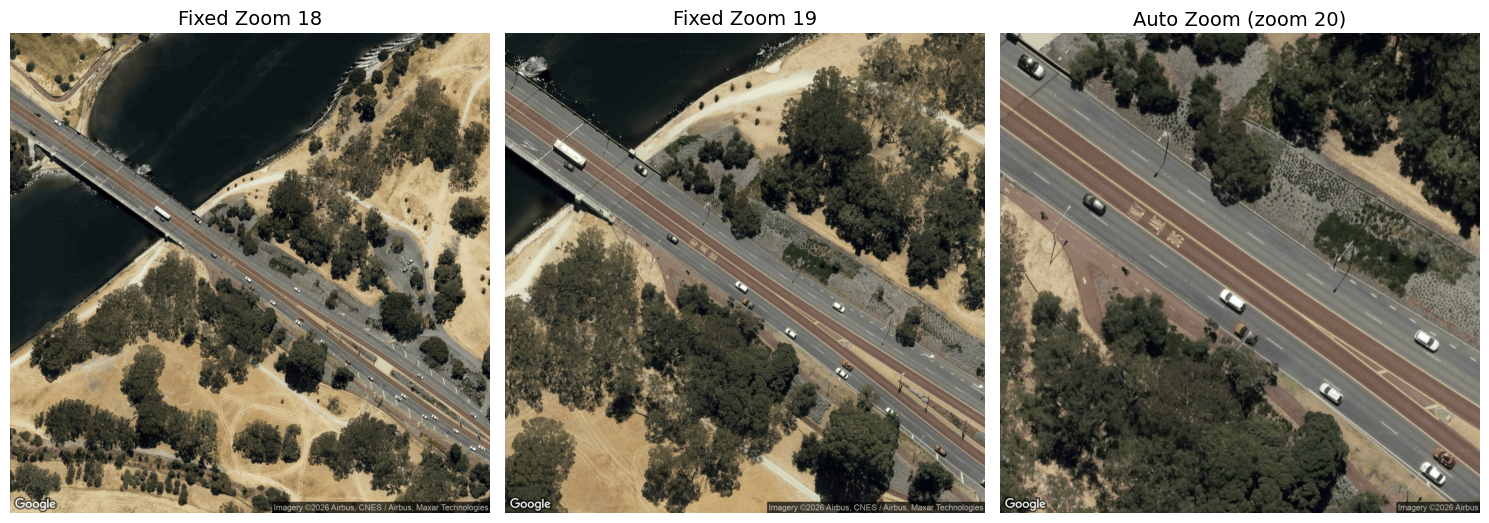

Saved figures/figure1_zoom_comparison.png


In [12]:
FIGURE1_GROUP = segments_group_1
FIGURE1_SEGMENT = 5          # 1-based index within the group
FIGURE1_PATH = "figures/figure1_zoom_comparison.png"

s_lat, s_lon, e_lat, e_lon = FIGURE1_GROUP[FIGURE1_SEGMENT - 1]
auto_zoom = calculate_zoom(s_lat, s_lon, e_lat, e_lon)

panels = [
    ("Fixed Zoom 18", get_area_image(s_lat, s_lon, e_lat, e_lon, api_key, zoom=18)),
    ("Fixed Zoom 19", get_area_image(s_lat, s_lon, e_lat, e_lon, api_key, zoom=19)),
    (f"Auto Zoom (zoom {auto_zoom})", get_area_image(s_lat, s_lon, e_lat, e_lon, api_key)),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
for ax, (title, img) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=14)
    ax.axis("off")
plt.tight_layout()

os.makedirs(os.path.dirname(FIGURE1_PATH), exist_ok=True)
fig.savefig(FIGURE1_PATH, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {FIGURE1_PATH}")

### Evaluation of Zoom Levels for Feature Extraction

**Fixed Zoom 18**

- This zoom level provides a wide view of the area. However, it causes more than half of the image to overlap with adjacent segments. As a result, there is a high risk that the AI model might extract features from neighboring segments or overcount the building density.

**Fixed Zoom 19**
- This level offers the best balance. The image resolution is high enough to easily identify small features such as sidewalks and white lines. At the same time, it captures enough of the surrounding area. It is the most efficient and reliable choice for AI processing.

**Auto Zoom**
- This method is useful for fitting the entire road segment into a single image. The main problem is that the resolution changes depending on the length of the road. This inconsistent level of detail makes it hard for the AI model to perform stably across different areas.

**Final Conclusion:**

Therefore, among these three options, **Fixed Zoom 19** is the most practical and reliable approach for the AusRAP pedestrian analysis. It provides stable and clear images, ensuring the AI model can extract features accurately without double-counting.

## Exploring the Trimmed Fixed Zoom 19 Approach

### Calculate the (x, y) pixel coordinates of a given lat/lon

In [13]:
import math

def latlon_to_pixel(lat, lon, center_lat, center_long, zoom, actual_img_size=1280):
    """
    Calculate the (x, y) pixel coordinates of a given lat/lon
    within the downloaded static map image.
    """
    TILE_SIZE = 256

    # Inner function to project lat/lon to global Web Mercator coordinates (zoom level 0)
    def project(lat, lon):
        siny = math.sin(math.radians(lat))
        siny = min(max(siny, -0.9999), 0.9999) # Prevent infinity at the poles
        x = TILE_SIZE * (0.5 + lon / 360.0)
        y = TILE_SIZE * (0.5 - math.log((1 + siny) / (1 - siny)) / (4 * math.pi))
        return x, y

    # Project both the center point and the target point
    cx, cy = project(center_lat, center_long)
    px, py = project(lat, lon)

    # Calculate the scale factor.
    # Multiply by 2 because the API's scale=2 doubles the actual pixel resolution.
    map_scale = (2 ** zoom) * 2

    # Calculate pixel differences from the center
    dx = (px - cx) * map_scale
    dy = (py - cy) * map_scale

    # Convert to image coordinates (Top-Left is 0,0)
    center_px = actual_img_size / 2.0
    img_x = center_px + dx
    img_y = center_px + dy

    return img_x, img_y

### Fetch a fixed zoom image and crop it into a square bounding box.

In [14]:
import PIL.Image

def get_trimmed_area_image(start_lat, start_long, end_lat, end_long, api_key, zoom=19, img_size=640, margin=0):
    """
    Fetch a fixed zoom image and crop it into a square bounding box.
    'margin' adds extra pixels around the segment to ensure sidewalks are included.
    """
    # 1. Fetch the raw fixed-zoom image
    center_lat, center_long = calculate_center(start_lat, start_long, end_lat, end_long)
    raw_image = fetch_static_map_image(center_lat, center_long, zoom, api_key, img_size)

    actual_img_size = img_size * 2 # Due to scale=2

    # 2. Calculate pixel coordinates for the start and end points
    start_x, start_y = latlon_to_pixel(start_lat, start_long, center_lat, center_long, zoom, actual_img_size)
    end_x, end_y = latlon_to_pixel(end_lat, end_long, center_lat, center_long, zoom, actual_img_size)

    # 3. Calculate the dimensions to create a square bounding box
    bbox_width = abs(start_x - end_x)
    bbox_height = abs(start_y - end_y)

    # Find the maximum side length to ensure the crop area forms a square
    max_side = max(bbox_width, bbox_height)
    half_side = (max_side / 2.0) + margin

    # Determine the center pixel of the road segment
    center_px_x = (start_x + end_x) / 2.0
    center_px_y = (start_y + end_y) / 2.0

    # Calculate the new square boundaries
    left = center_px_x - half_side
    right = center_px_x + half_side
    top = center_px_y - half_side
    bottom = center_px_y + half_side

    # 4. Clip the bounding box to the image boundaries to prevent errors
    left = max(0, left)
    right = min(actual_img_size, right)
    top = max(0, top)
    bottom = min(actual_img_size, bottom)

    # 5. Crop and return the image
    trimmed_image = raw_image.crop((left, top, right, bottom))

    return trimmed_image, raw_image

### Evaluate the Trimmed Fixed Zoom 19 Approach

Cropping removes the Google logo and imagery attribution from the trimmed images. These crops are for exploration only; any figure reused outside this notebook should use the uncropped images, which keep the attribution.

In [15]:
import matplotlib.pyplot as plt
# --- Testing the Trimmed View ---
TRIM_MARGIN = 150  # extra pixels around the segment's bounding box

print("=== Testing Trimmed Zoom 19 ===")
for index, (start_lat, start_long, end_lat, end_long) in enumerate(segments_group_1):
    # Fetch the trimmed image and the original raw image for comparison
    trimmed_img, raw_img = get_trimmed_area_image(start_lat, start_long, end_lat, end_long, api_key, zoom=19, margin=TRIM_MARGIN)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original Raw Image
    axes[0].imshow(raw_img)
    axes[0].set_title(f"Seg {index + 1} | Raw Zoom 19", fontsize=14)
    axes[0].axis("off")

    # Trimmed Image
    axes[1].imshow(trimmed_img)
    axes[1].set_title(f"Seg {index + 1} | Trimmed (Margin={TRIM_MARGIN})", fontsize=14, fontweight="bold")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Evaluation of the Trimmed Approach

**Observation:**
Fixed Zoom 19 is generally sufficient for practical use. However, applying the trimming method significantly reduces the overlap between adjacent segments. This reduction is especially noticeable when comparing Segment 4 and Segment 5.

**Conclusion:**
By decreasing the overlapped areas, the trimmed images can represent the unique features of each specific segment much more accurately.